<a href="https://colab.research.google.com/github/dhavltharkaaar/Hand_Written_Classification/blob/main/Project_Hand_Written_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


Unzip the dataset

In [2]:
!unzip '/content/gdrive/MyDrive/Colab Notebooks/Hand_Written/Hand_Written_Classification.zip'

Streaming output truncated to the last 5000 lines.
  inflating: Hand_Written_Classification/ja/ja (49).jpg  
  inflating: Hand_Written_Classification/ja/ja (5).jpg  
  inflating: Hand_Written_Classification/ja/ja (50).jpg  
  inflating: Hand_Written_Classification/ja/ja (51).jpg  
  inflating: Hand_Written_Classification/ja/ja (52).jpg  
  inflating: Hand_Written_Classification/ja/ja (53).jpg  
  inflating: Hand_Written_Classification/ja/ja (54).jpg  
  inflating: Hand_Written_Classification/ja/ja (55).jpg  
  inflating: Hand_Written_Classification/ja/ja (56).jpg  
  inflating: Hand_Written_Classification/ja/ja (57).jpg  
  inflating: Hand_Written_Classification/ja/ja (58).jpg  
  inflating: Hand_Written_Classification/ja/ja (59).jpg  
  inflating: Hand_Written_Classification/ja/ja (6).jpg  
  inflating: Hand_Written_Classification/ja/ja (60).jpg  
  inflating: Hand_Written_Classification/ja/ja (61).jpg  
  inflating: Hand_Written_Classification/ja/ja (62).jpg  
  inflating: Hand_Writt

Import the necessary libraries

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras.models import Sequential
from keras.layers import Dense
from keras.layers import LSTM
from keras.layers import Dropout
import numpy as np

Loading Dataset Directory to acess the dataset

In [7]:
base_dir = r"/content/Hand_Written_Classification"

# Spliting the Dataset into train dataset and test dataset

We have total 10 alphabet of marrathi language each character has 200 images as dataset.

Overall we have 2000 images as dataset we have split it into train dataset and test dataset.

Train dataset contains 80 percentage of the dataset.

Test data contains the 20 percentage of the dataset


## Data preparation - cleansing and preparing data for the next steps of model development

In [8]:
IMAGE_SIZE=224
BATCH_SIZE=64

#Loading Custom image dataset and Preprocess it
train=tf.keras.preprocessing.image.ImageDataGenerator(
    rescale=1./255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    validation_split=0.2
    )

test=tf.keras.preprocessing.image.ImageDataGenerator(
     rescale=1./255,
     validation_split=0.2
)

train=train.flow_from_directory(
    base_dir,
    target_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    subset='training'
)

test=test.flow_from_directory(
    base_dir,
    target_size=(IMAGE_SIZE,IMAGE_SIZE),
    batch_size=BATCH_SIZE,
    subset='validation'
)

Found 7872 images belonging to 48 classes.
Found 1968 images belonging to 48 classes.


### Training and testing the dataset into X_train,X_test, y_train and y_test

In [10]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(test,test,test_size=0.2)

### Building Convolutional Neural Networks

In [11]:
cnn=tf.keras.Sequential()
cnn.add(tf.keras.layers.Conv2D(filters=64,padding='same',strides=2,kernel_size=3,activation='relu',input_shape=(224,224,3)))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=32,padding='same',strides=2,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=32,padding='same',strides=2,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(48,activation='softmax')) #Activation function sigmoid is used to get accuracy

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [12]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(),loss='categorical_crossentropy',metrics=['accuracy'])

In [13]:
r=cnn.fit(train,epochs=50,validation_data=test)

Epoch 1/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 301s 2s/step - accuracy: 0.0268 - loss: 3.8432 - val_accuracy: 0.0610 - val_loss: 3.6862
Epoch 2/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 286s 2s/step - accuracy: 0.1786 - loss: 3.1267 - val_accuracy: 0.2368 - val_loss: 2.9056
Epoch 3/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 328s 2s/step - accuracy: 0.3422 - loss: 2.3820 - val_accuracy: 0.3308 - val_loss: 2.3743
Epoch 4/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 297s 2s/step - accuracy: 0.4625 - loss: 1.8948 - val_accuracy: 0.4238 - val_loss: 2.0176
Epoch 5/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 295s 2s/step - accuracy: 0.5343 - loss: 1.6231 - val_accuracy: 0.4721 - val_loss: 1.8382
Epoch 6/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 316s 2s/step - accuracy: 0.5621 - loss: 1.4980 - val_accuracy: 0.4914 - val_loss: 1.7336
Epoch 7/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 291s 2s/step - accuracy: 0.6011 - loss: 1.3844 - val_accuracy: 0.5401 - val_loss: 1.6156
Epoch 8/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 296s 2s/step - accuracy: 0.6203 - loss: 1.3034 - val_accu

In [15]:
train_loss, train_acc = cnn.evaluate(train, steps=16)
val_loss, val_acc = cnn.evaluate(test, steps=16)

print('Train accuracy : %.3f, Test accuracy : %.3f' % (train_acc, val_acc))

16/16 ━━━━━━━━━━━━━━━━━━━━ 24s 1s/step - accuracy: 0.8447 - loss: 0.5119
16/16 ━━━━━━━━━━━━━━━━━━━━ 7s 438ms/step - accuracy: 0.7461 - loss: 0.9232
Train accuracy : 0.845, Test accuracy : 0.746


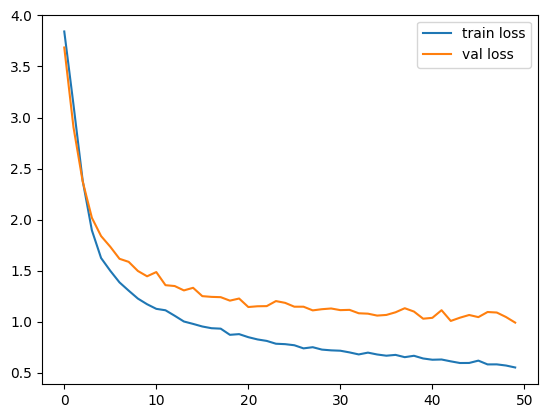

In [18]:
#plot the loss
plt.plot(r.history['loss'], label = 'train loss')
plt.plot(r.history['val_loss'], label = 'val loss')
plt.legend()
plt.show()
#plt.savefig('LossVal_loss')

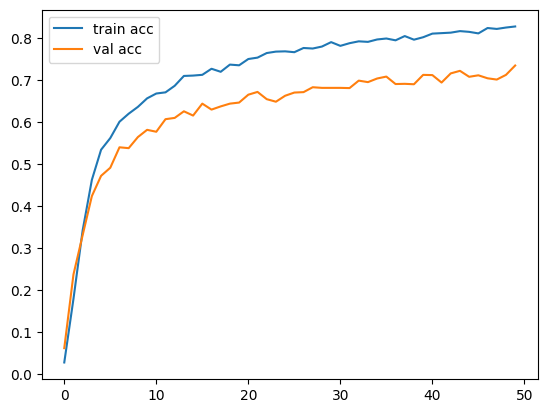

In [19]:
#plot the accuracy
plt.plot(r.history['accuracy'], label = 'train acc')
plt.plot(r.history['val_accuracy'], label = 'val acc')
plt.legend()
plt.show()
#plt.savefig('Actual_acc')

# Saving the model

In [21]:
cnn.save_weights('/content/gdrive/MyDrive/Colab Notebooks/Hand_Written/cnn.weights.h5')